# Pneumonia Detection from Chest X-Rays (PneumoniaMNIST)

Real pediatric chest x-rays from the Guangzhou Women and Children's Medical Center set (Kermany et al., 2018, CC BY 4.0), the same images behind the popular Kaggle "chest x-ray pneumonia" dataset. I use the preprocessed PneumoniaMNIST version from MedMNIST v2 (Yang et al., 2023): 5,856 grayscale images resized to 64x64, with the official train / val / test split (4,708 / 524 / 624). The `.npz` file comes straight from MedMNIST's Zenodo record.

Pneumonia is genuinely hard to call from a single x-ray, even for radiologists, and 64x64 throws away a lot of detail. **Loud disclaimer: this is not a clinical model.** It's a small CNN trained for a few epochs on CPU to show the pipeline on real data.

In [1]:
import urllib.request
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
device = "cpu"
print("device:", device)

device: cpu


## Load PneumoniaMNIST (64x64)

train images: (4708, 64, 64)  pneumonia share: 0.742
val   images: (524, 64, 64)  pneumonia share: 0.742
test  images: (624, 64, 64)  pneumonia share: 0.625


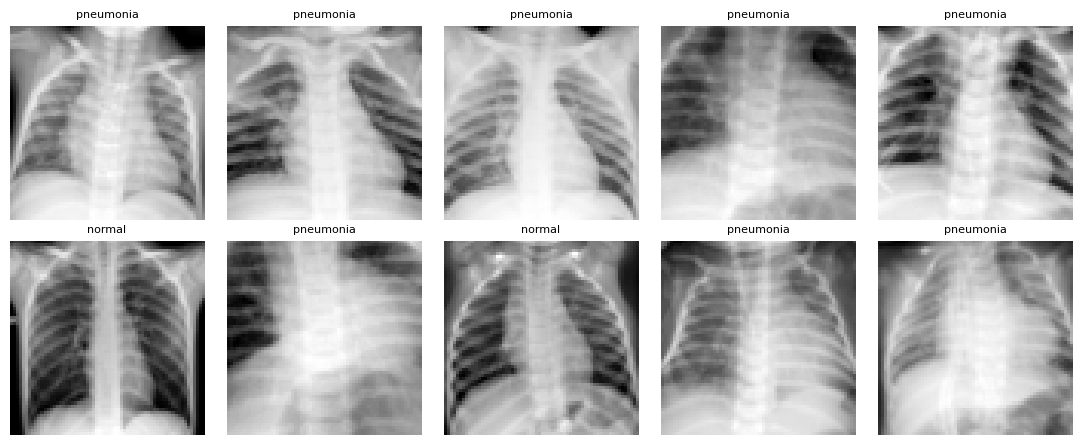

In [2]:
DATA = Path("../../data/medmnist")
NPZ = DATA / "pneumoniamnist_64.npz"
if not NPZ.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1", NPZ)
d = np.load(NPZ)
splits = {s: (d[f"{s}_images"].astype(np.float32) / 255.0, d[f"{s}_labels"].ravel().astype(np.int64))
          for s in ["train", "val", "test"]}
for s, (x, y) in splits.items():
    print(f"{s:5s} images: {x.shape}  pneumonia share: {y.mean():.3f}")

imgs, labels = splits["train"]
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i], cmap="gray")
    ax.set_title("pneumonia" if labels[i] else "normal", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Small CNN

Trained on the official train split with class-weighted loss (about 74% of training images are pneumonia), 6 epochs.

In [3]:
class TinyXrayCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Linear(64, 2),
        )
    def forward(self, x): return self.net(x)

def loader(split, shuffle):
    x, y = splits[split]
    return DataLoader(TensorDataset(torch.tensor(x).unsqueeze(1), torch.tensor(y)), batch_size=64, shuffle=shuffle)
tr_dl, te_dl = loader("train", True), loader("test", False)

model = TinyXrayCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
counts = np.bincount(splits['train'][1])
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32))

for ep in range(6):
    model.train(); total, n = 0, 0
    for xb, yb in tr_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); out = model(xb)
        loss = loss_fn(out, yb); loss.backward(); opt.step()
        total += loss.item() * xb.size(0); n += xb.size(0)
    print(f"ep {ep+1}  train_loss={total/n:.3f}")

ep 1  train_loss=0.675


ep 2  train_loss=0.535


ep 3  train_loss=0.409


ep 4  train_loss=0.333


ep 5  train_loss=0.320


ep 6  train_loss=0.291


## Eval

In [4]:
model.eval()
ys, ps, scores = [], [], []
with torch.no_grad():
    for xb, yb in te_dl:
        xb = xb.to(device)
        logits = model(xb)
        prob = torch.softmax(logits, 1)[:, 1].cpu().numpy()
        ys.extend(yb.tolist()); ps.extend(logits.argmax(1).cpu().tolist()); scores.extend(prob.tolist())

print(classification_report(ys, ps, target_names=["normal", "pneumonia"], digits=3))
try:
    print(f"AUC: {roc_auc_score(ys, scores):.3f}")
except ValueError: pass
print("confusion:\n", confusion_matrix(ys, ps))

              precision    recall  f1-score   support

      normal      0.839     0.735     0.784       234
   pneumonia      0.852     0.915     0.883       390

    accuracy                          0.848       624
   macro avg      0.846     0.825     0.833       624
weighted avg      0.847     0.848     0.845       624

AUC: 0.926
confusion:
 [[172  62]
 [ 33 357]]


## What this is and isn't

On the official 624-image test split the small CNN gets 84.8% accuracy and ROC-AUC 0.926. It catches 91.5% of pneumonia cases (357 of 390) but also calls 62 of 234 normal x-rays pneumonia. Note the test set has a different class mix from training (62.5% pneumonia vs 74.2%), which is how the original Kermany split was built.

Is: a working pipeline on real x-rays. The data loading, class-weighted training loop and evaluation report are the parts I'd keep.

Isn't: anything that should inform a clinical decision. 64x64 inputs throw away most of the detail a radiologist would use, these are pediatric x-rays from a single center, and this dataset is known to have quirks (image sources and labels that a model can partly learn shortcuts from), so a high score here doesn't mean it would transfer to adult x-rays from another hospital.

For a real attempt I'd use the RSNA Pneumonia Detection dataset or the full-resolution images, a pretrained DenseNet-121 (or CheXNet / TorchXRayVision weights as a starting point), and report sensitivity at a fixed operating point with bootstrapped confidence intervals, tested on an external hospital.